# Практическая работа №1. Основные методы OpenCV. Часть №1

In [1]:
from pathlib import Path
import tempfile
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from IPython import get_ipython
from matplotlib_inline.backend_inline import set_matplotlib_formats

get_ipython().run_line_magic('matplotlib', 'inline')
set_matplotlib_formats('jpeg', pil_kwargs={'quality': 82})
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
cv2.setNumThreads(2)

workdir = tempfile.TemporaryDirectory()
LAB = Path(workdir.name)
OUT = LAB / 'results'
OUT.mkdir()
EXAMPLES = LAB / 'images' / 'examples'
EXAMPLES.mkdir(parents=True)
cv2.imwrite(str(EXAMPLES / 'coffee.jpg'), cv2.cvtColor(data.coffee(), cv2.COLOR_RGB2BGR),
            [cv2.IMWRITE_JPEG_QUALITY, 94])
cv2.imwrite(str(EXAMPLES / 'chelsea.jpg'), cv2.cvtColor(data.chelsea(), cv2.COLOR_RGB2BGR),
            [cv2.IMWRITE_JPEG_QUALITY, 94])
cv2.imwrite(str(EXAMPLES / 'page.png'), data.page());

In [2]:
def read_image(path, flags=cv2.IMREAD_COLOR):
    image = cv2.imread(str(path), flags)
    if image is None:
        raise FileNotFoundError(f'Не удалось прочитать {path}')
    return image


def rgb_for_plot(image):
    if image.ndim == 2:
        return image
    conversion = cv2.COLOR_BGRA2RGBA if image.shape[2] == 4 else cv2.COLOR_BGR2RGB
    return cv2.cvtColor(image, conversion)


def show_images(items, filename=None, cols=2):
    rows = (len(items) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 3.5 * rows), squeeze=False)
    for ax, (title, image) in zip(axes.flat, items):
        h, w = image.shape[:2]
        scale = min(1, 650 / max(h, w))
        small = cv2.resize(image, (max(1, round(w * scale)), max(1, round(h * scale))),
                           interpolation=cv2.INTER_AREA)
        ax.imshow(rgb_for_plot(small), cmap='gray', vmin=0, vmax=255)
        ax.set_title(title)
        ax.axis('off')
    for ax in list(axes.flat)[len(items):]:
        ax.axis('off')
    fig.tight_layout()
    if filename:
        fig.savefig(OUT / filename, dpi=120, bbox_inches='tight', pil_kwargs={'quality': 88})
    plt.show()
    plt.close(fig)


def save_image(name, image):
    if not cv2.imwrite(str(OUT / name), image):
        raise OSError(f'Не удалось сохранить {name}')

# Тема №1. Чтение, запись и отображение

## Задание 1:  
Напишите процедуру, которая:

- Считывает цветное изображение в режиме `cv2.IMREAD_COLOR`.
- Преобразует его в оттенки серого с использованием `cv2.cvtColor()`.
- Сохраняет полученное черно-белое изображение на диск.
- Отображает оба изображения (оригинальное цветное и преобразованное черно-белое).

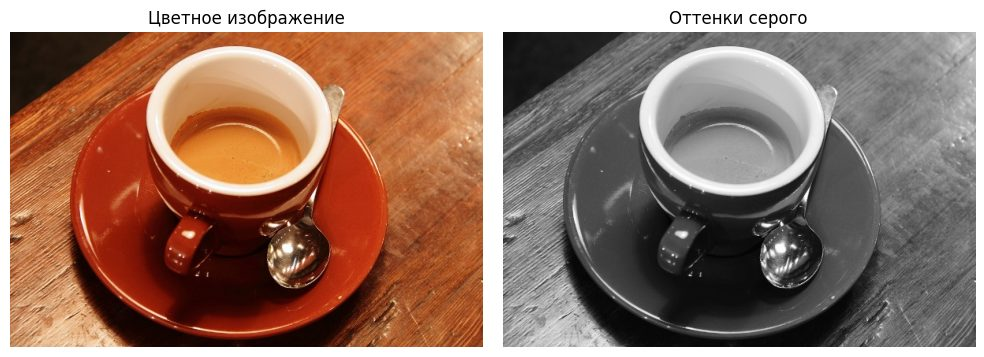

In [3]:
coffee = read_image(EXAMPLES / 'coffee.jpg', cv2.IMREAD_COLOR)
gray = cv2.cvtColor(coffee, cv2.COLOR_BGR2GRAY)
save_image('01_coffee_gray.png', gray)
show_images([('Цветное изображение', coffee), ('Оттенки серого', gray)], '01_grayscale.jpg')

## Задание 2:  
Используя режим `cv2.IMREAD_UNCHANGED`, загрузите изображение с альфа-каналом (например, PNG с прозрачностью). Затем:

- Разделите изображение на каналы (B, G, R, A).
- Создайте новое изображение, где прозрачность (альфа-канал) инвертирована (т.е. прозрачные области становятся непрозрачными и наоборот).
- Сохраните и отобразите полученное изображение.

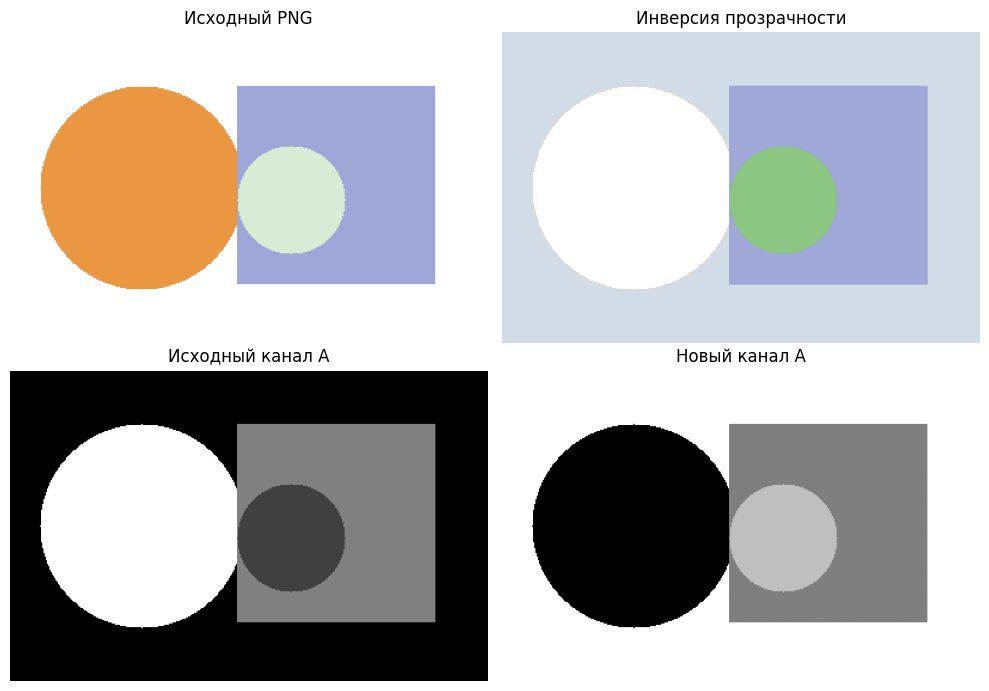

In [4]:
alpha_sample = np.full((260, 400, 4), (230, 220, 210, 0), dtype=np.uint8)
cv2.circle(alpha_sample, (110, 130), 85, (65, 150, 235, 255), -1)
cv2.rectangle(alpha_sample, (190, 45), (355, 210), (180, 80, 65, 128), -1)
cv2.circle(alpha_sample, (235, 140), 45, (90, 180, 100, 64), -1)
save_image('02_alpha_original.png', alpha_sample)

bgra = read_image(OUT / '02_alpha_original.png', cv2.IMREAD_UNCHANGED)
b, g, r, a = cv2.split(bgra)
inverted_alpha = 255 - a
inverted = cv2.merge((b, g, r, inverted_alpha))
save_image('02_alpha_inverted.png', inverted)
show_images([('Исходный PNG', bgra), ('Инверсия прозрачности', inverted),
             ('Исходный канал A', a), ('Новый канал A', inverted_alpha)],
            '02_alpha_comparison.jpg')

# Тема №2. Работа с цветовыми палитрами

## Задание 3:  
Напишите процедуру, которая:

- Считывает цветное изображение.
- Преобразует его из цветового пространства BGR в HSV с помощью `cv2.cvtColor()`.
- Увеличивает насыщенность (канал S) в 1.5 раза, не превышая максимального значения.
- Преобразует изображение обратно в цветовое пространство BGR.
- Отображает оригинальное и полученное изображения рядом для сравнения.

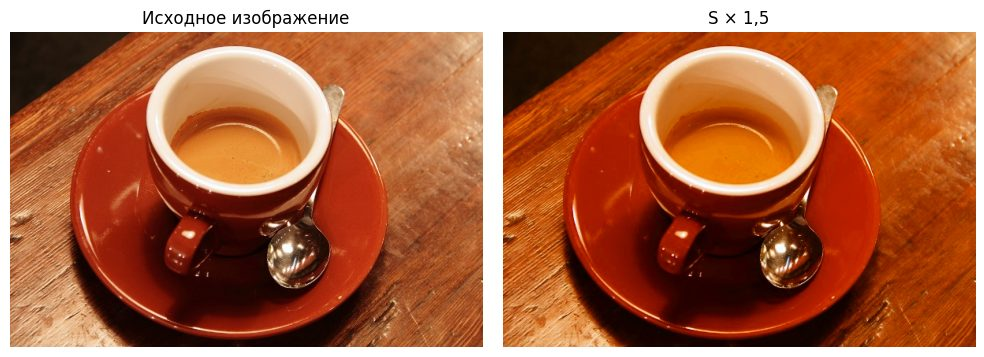

In [5]:
coffee = read_image(EXAMPLES / 'coffee.jpg')
hsv = cv2.cvtColor(coffee, cv2.COLOR_BGR2HSV)
h, s, v = cv2.split(hsv)
s_new = np.clip(s.astype(np.float32) * 1.5, 0, 255).astype(np.uint8)
saturated = cv2.cvtColor(cv2.merge((h, s_new, v)), cv2.COLOR_HSV2BGR)
save_image('03_saturation.png', saturated)
show_images([('Исходное изображение', coffee), ('S × 1,5', saturated)], '03_hsv.jpg')

## Задание 4:  
Напишите процедуру, которая:

- Считывает изображение и Преобразует его в цветовое пространство YCrCb.
- Применяет размытие к компоненте яркости Y (при помощи фильтра, см. материал предыдущих занятий).
- Снова Преобразует изображение в цветовое пространство BGR.
- Отображает исходное и размытое изображения.

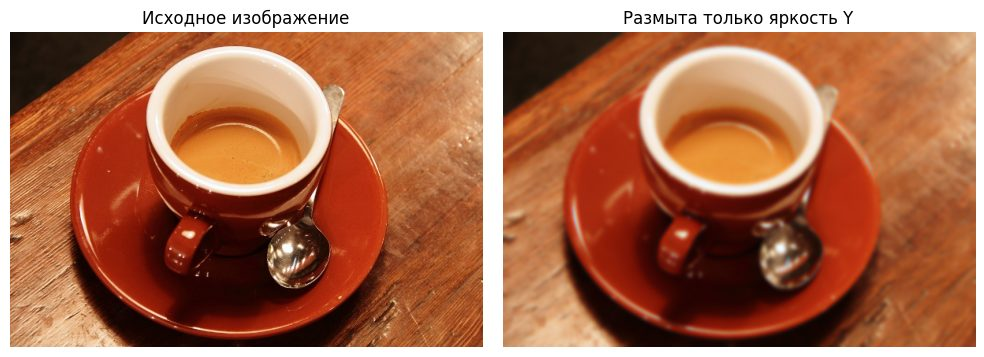

In [6]:
coffee = read_image(EXAMPLES / 'coffee.jpg')
ycrcb = cv2.cvtColor(coffee, cv2.COLOR_BGR2YCrCb)
y, cr, cb = cv2.split(ycrcb)
y_blur = cv2.GaussianBlur(y, (13, 13), 0)
blurred_y = cv2.cvtColor(cv2.merge((y_blur, cr, cb)), cv2.COLOR_YCrCb2BGR)
save_image('04_y_blur.png', blurred_y)
show_images([('Исходное изображение', coffee), ('Размыта только яркость Y', blurred_y)],
            '04_ycrcb.jpg')

# Тема №3. Слияние и усиление

## Задание 5:  
Создайте процедуру, которая:

- Считывает два изображения одинакового размера (можно подкорректировать с помощью метода `.resize()`).
- Выполняет побитовое ИЛИ (OR) над соответствующими пикселями двух изображений.
- Сохраняет и отображает результат операции.

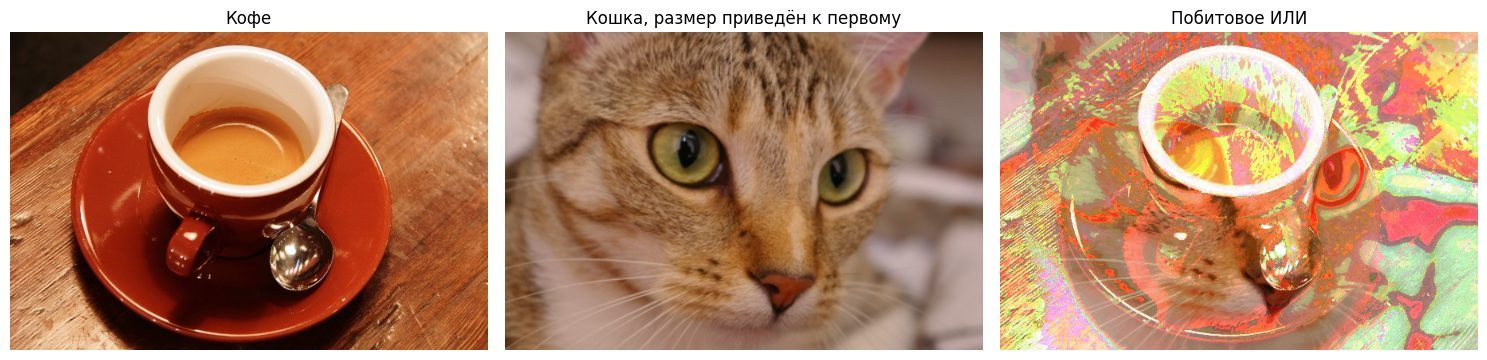

In [7]:
cat = read_image(EXAMPLES / 'chelsea.jpg')
cat_resized = cv2.resize(cat, (coffee.shape[1], coffee.shape[0]), interpolation=cv2.INTER_LINEAR)
or_result = cv2.bitwise_or(coffee, cat_resized)
save_image('05_bitwise_or.png', or_result)
show_images([('Кофе', coffee), ('Кошка, размер приведён к первому', cat_resized),
             ('Побитовое ИЛИ', or_result)], '05_or.jpg', cols=3)

## Задание 6:  
Реализуйте следующий алгоритм:

- Считайте цветное изображение и разделите его на три канала с использованием `.split()`.
- Примените к каждому каналу разный коэффициент гамма-коррекции (например, для R – 0.5, G – 1.0, B – 1.5).
- Объедините каналы обратно с помощью `.merge()`.
- Отобразите исходное и обработанное изображения.

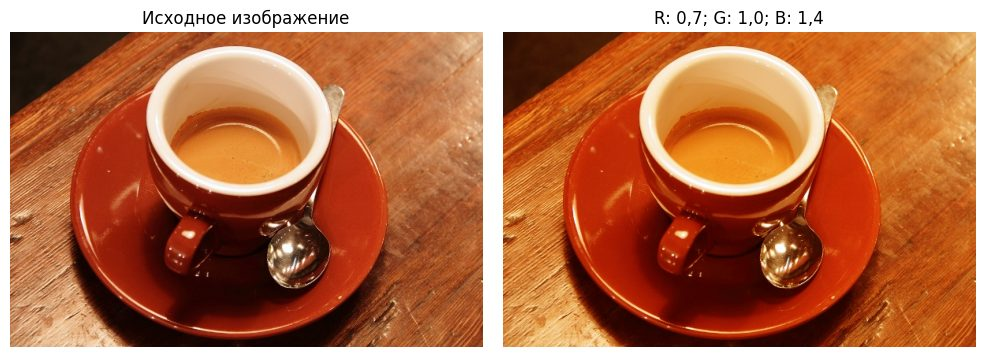

In [8]:
coffee = read_image(EXAMPLES / 'coffee.jpg')
def gamma_channel(channel, gamma):
    if gamma <= 0:
        raise ValueError('Гамма должна быть больше нуля')
    table = np.round(255 * (np.arange(256) / 255.0) ** gamma).astype(np.uint8)
    return cv2.LUT(channel, table)

b, g, r = cv2.split(coffee)
gamma_result = cv2.merge((gamma_channel(b, 1.4), gamma_channel(g, 1.0),
                          gamma_channel(r, 0.7)))
save_image('06_gamma_channels.png', gamma_result)
show_images([('Исходное изображение', coffee), ('R: 0,7; G: 1,0; B: 1,4', gamma_result)],
            '06_gamma.jpg')

# Тема №4. Работа с гистограммами в OpenCV

## Задание 7:  
Напишите процедуру для улучшения контрастности изображения:

- Считывает изображение в оттенках серого.
- Строит его гистограмму с использованием `cv.calcHist()`.
- Применяет эквализацию гистограммы методом `cv2.equalizeHist()`.
- Отображает на одном графике исходное и эквализованное изображения вместе с их гистограммами.

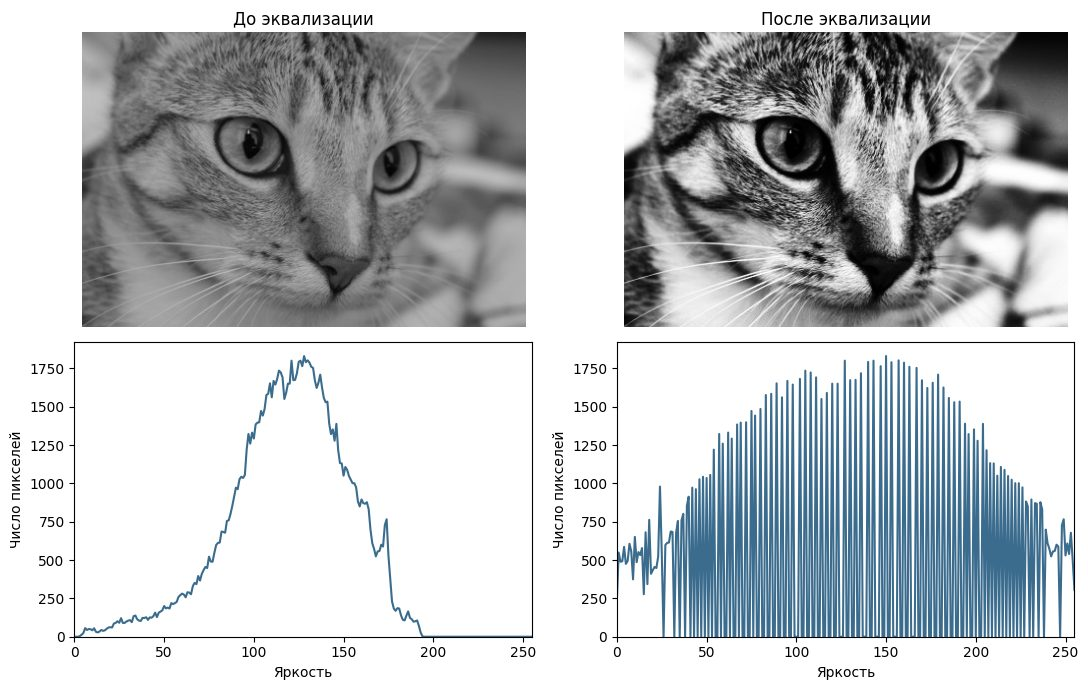

In [9]:
cat_gray = read_image(EXAMPLES / 'chelsea.jpg', cv2.IMREAD_GRAYSCALE)
equalized = cv2.equalizeHist(cat_gray)
save_image('07_equalized.png', equalized)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, (title, image) in enumerate([('До эквализации', cat_gray), ('После эквализации', equalized)]):
    axes[0, col].imshow(image, cmap='gray', vmin=0, vmax=255)
    axes[0, col].set_title(title)
    axes[0, col].axis('off')
    histogram = cv2.calcHist([image], [0], None, [256], [0, 256])
    axes[1, col].plot(np.arange(256), histogram.ravel(), color='#3b6c8e')
    axes[1, col].set(xlim=(0, 255), xlabel='Яркость', ylabel='Число пикселей')
limit = max(ax.get_ylim()[1] for ax in axes[1])
for ax in axes[1]:
    ax.set_ylim(0, limit)
fig.tight_layout()
fig.savefig(OUT / '07_histograms.png', dpi=120)
plt.show()
plt.close(fig)

## Задание 8:  
Используйте метод CLAHE для улучшения деталей в затемненных областях цветного изображения:

- Преобразуйте изображение из BGR в LAB цветовое пространство.
- Разделите изображение на каналы и примените `cv2.createCLAHE()` к каналу яркости L.
- Объедините обработанный канал L с исходными каналами A и B.
- Преобразуйте изображение обратно в BGR.
- Отобразите исходное и обработанное изображения для сравнения вместе с их гистограммами.

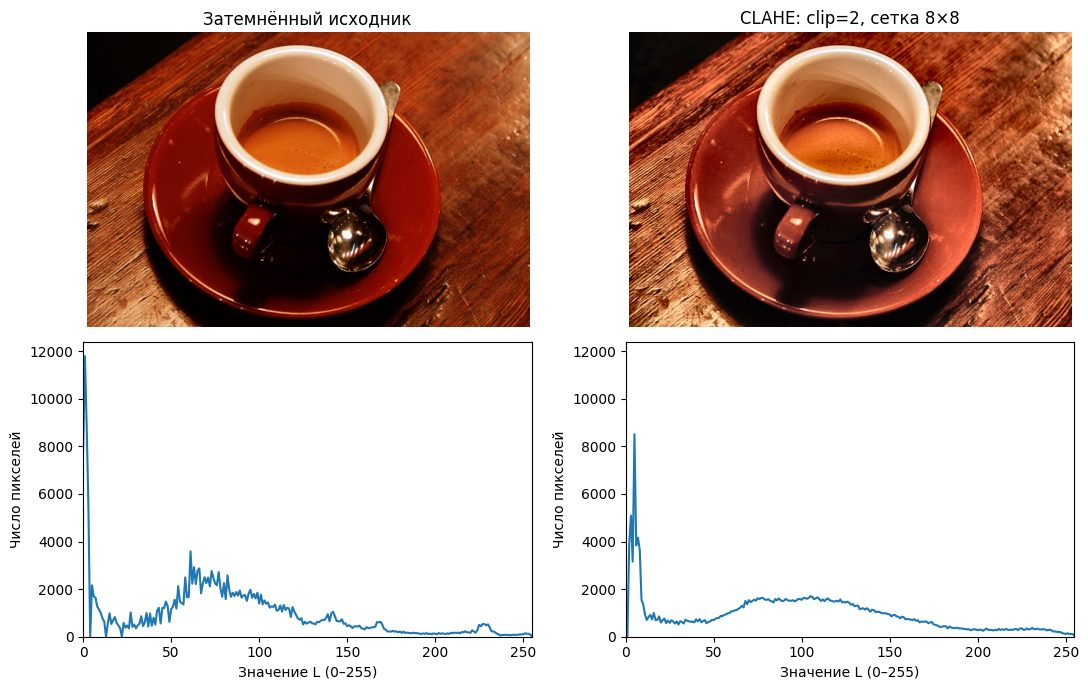

In [10]:
dark = cv2.LUT(coffee, np.round(255 * (np.arange(256) / 255.0) ** 1.8).astype(np.uint8))
save_image('08_dark_input.png', dark)

def clahe_color(image, clip=2.0, grid=(8, 8)):
    l, a, b = cv2.split(cv2.cvtColor(image, cv2.COLOR_BGR2LAB))
    l_new = cv2.createCLAHE(clipLimit=clip, tileGridSize=grid).apply(l)
    result = cv2.cvtColor(cv2.merge((l_new, a, b)), cv2.COLOR_LAB2BGR)
    return result, l, l_new

clahe_result, l_before, l_after = clahe_color(dark)
save_image('08_clahe.png', clahe_result)
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for col, (title, image, lightness) in enumerate([
        ('Затемнённый исходник', dark, l_before), ('CLAHE: clip=2, сетка 8×8', clahe_result, l_after)]):
    axes[0, col].imshow(rgb_for_plot(image))
    axes[0, col].set_title(title)
    axes[0, col].axis('off')
    axes[1, col].plot(cv2.calcHist([lightness], [0], None, [256], [0, 256]).ravel())
    axes[1, col].set(xlim=(0, 255), xlabel='Значение L (0–255)', ylabel='Число пикселей')
limit = max(ax.get_ylim()[1] for ax in axes[1])
for ax in axes[1]:
    ax.set_ylim(0, limit)
fig.tight_layout()
fig.savefig(OUT / '08_clahe_histograms.png', dpi=120)
plt.show()
plt.close(fig)

## Затем:  
Исследуйте влияние размера окна (tileGridSize) и порога по сравнению с гистограммой (clipLimit) в методе CLAHE на конечный результат. Попробуйте несколько различных значений и визуализируйте результаты.

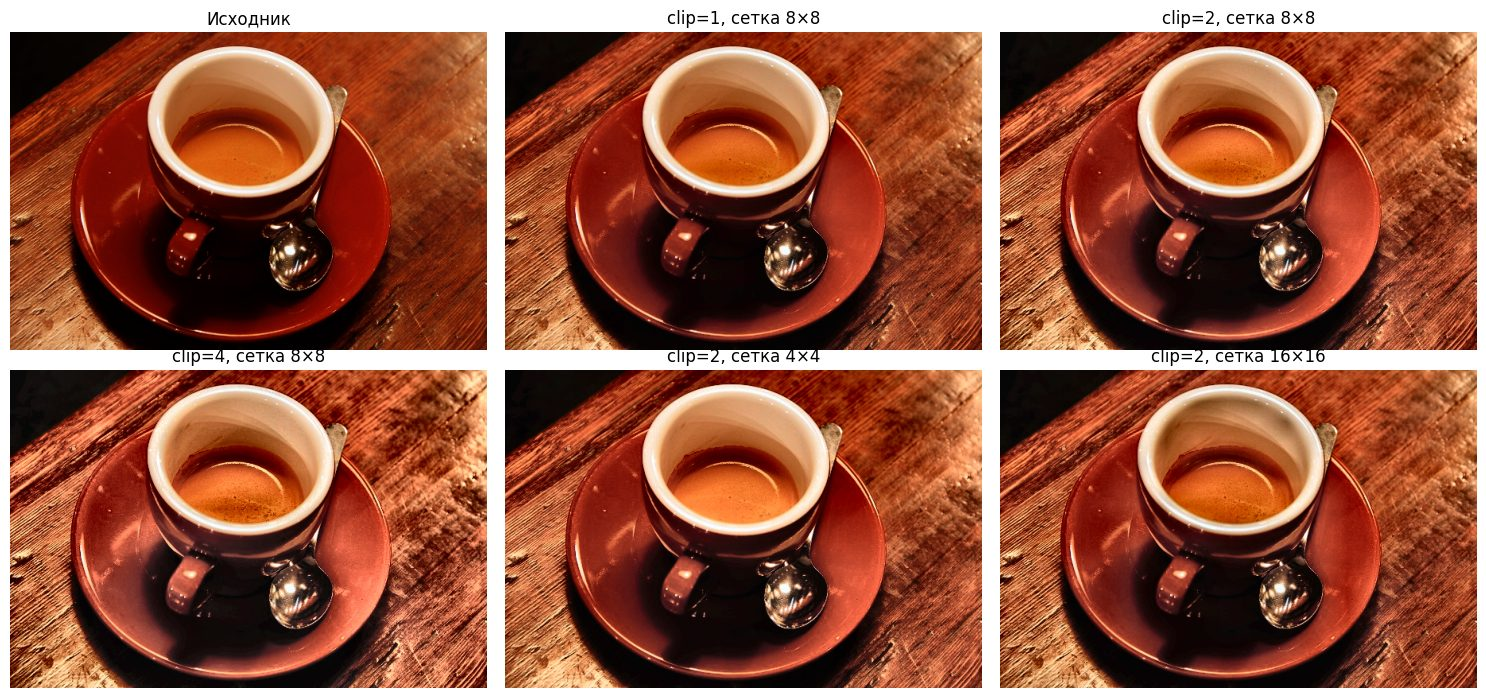

In [11]:
settings = [(1.0, (8, 8)), (2.0, (8, 8)), (4.0, (8, 8)),
            (2.0, (4, 4)), (2.0, (16, 16))]
variants = [('Исходник', dark)]
for clip, grid in settings:
    result, _, _ = clahe_color(dark, clip, grid)
    variants.append((f'clip={clip:g}, сетка {grid[0]}×{grid[1]}', result))
show_images(variants, '08_clahe_parameters.jpg', cols=3)

При clipLimit=4 контраст усилился, но тёмные участки стали грубее. Сетка 16×16 сильнее проявляет мелкую фактуру. Для этого изображения оставил clipLimit=2 и сетку 8×8.

# Комплексное задание №1. Улучшение качества отсканированного документа с использованием OpenCV

## Краткое описание задания:

- Необходимо написать функцию для улучшения качества отсканированного документа с использованием методов обработки изображений, изученных ранее. Функция должна принимать на вход изображение отсканированного документа и возвращать его улучшенную версию, готовую для дальнейшего использования, например, для распознавания текста.

Датасет с отсканированными изображениями можно найти в сети Интернет.

---

## Алгоритм действий:

#### Реализуйте функцию на языке Python с использованием библиотеки OpenCV, которая выполняет следующие этапы обработки:

### 1. Чтение, запись и отображение изображений:

- Функция должна принимать на вход изображение отсканированного документа (например, в формате JPEG или PNG)
- Проверьте наличие альфа-канала в изображении и, если он присутствует, загрузите изображение в режиме `cv2.IMREAD_UNCHANGED`, иначе используйте `cv2.IMREAD_COLOR`
- Отобразите исходное изображение для визуальной проверки

### 2. Работа с цветовыми палитрами:

- Преобразуйте изображение в оттенки серого, используя `cv2.cvtColor()` с параметром `cv2.COLOR_BGR2GRAY`.
- Отобразите полученное изображение в оттенках серого.

### 3. Слияние и усиление:

- Примените медианный фильтр (`cv2.medianBlur()`) для удаления шумов с изображения. Выберите подходящий размер ядра (например, 3 или 5). Отобразите результат.
- Используйте фильтр сглаживания с применением прямой свертки (`cv2.filter2D()`) с заданным ядром для повышения четкости. Например, можно использовать фильтр "Unsharp Masking":
  - Создайте ядро для повышения резкости. Пример ядра:
    ```python
    kernel = np.array([[-1, -1, -1],
                       [-1,  9, -1],
                       [-1, -1, -1]])
    ```
  - Примените фильтр к изображению и отобразите результат.

### 4. Работа с гистограммами:

- Примените метод CLAHE (Contrast Limited Adaptive Histogram Equalization) для улучшения контрастности изображения:
  - Создайте объект CLAHE с параметрами `clipLimit=2.0` и `tileGridSize=(8,8)`.
  - Примените CLAHE к изображению.
  - отобразите результат.
- Постройте гистограммы яркости исходного и обработанного изображений для сравнения.

---

### Требования к функции:

- Функция должна называться: `improve_scan(image)`, где `image` — входное изображение в виде массива NumPy.
- Функция должна возвращать улучшенное изображение в виде массива NumPy.
- В ходе работы функция должна опционально отображать промежуточные результаты для наглядности (в условиях Colab использовать соответствующие методы вывода изображений). Для этого следует ввести отдельный параметр (например: `visible=True`) и реализовать с ним соответствующую логику.

---

### Дополнительные требования:

- Обработка ошибок:
  - Убедитесь, что функция корректно обрабатывает ситуации, когда на вход подается некорректное изображение.
  - Добавьте проверки на тип входных данных.

- Документация и комментарии:
  - Функция должна быть снабжена понятной документацией: опишите, какие преобраования выполняются и для чего.
  - Добавьте комментарии к основным участкам кода для пояснения выполняемых действий.

---

### Подсказки и рекомендации:

- Медианный фильтр:
  Функция `cv2.medianBlur(src, ksize)` принимает на вход изображение и размер ядра (должен быть нечетным числом).

- CLAHE:
  - Создайте объект CLAHE с помощью `cv2.createCLAHE(clipLimit, tileGridSize)`.
  - Примените метод `apply()` к изображению в оттенках серого.

- Отображение изображений в Google Colab:
  - Используйте `matplotlib.pyplot` для отображения изображений.
  - Помните, что `cv2.imread()` загружает изображения в формате BGR, поэтому для корректного отображения в Matplotlib Преобразуйте изображение в RGB с помощью `cv2.cvtColor(image, cv2.COLOR_BGR2RGB)`.

---

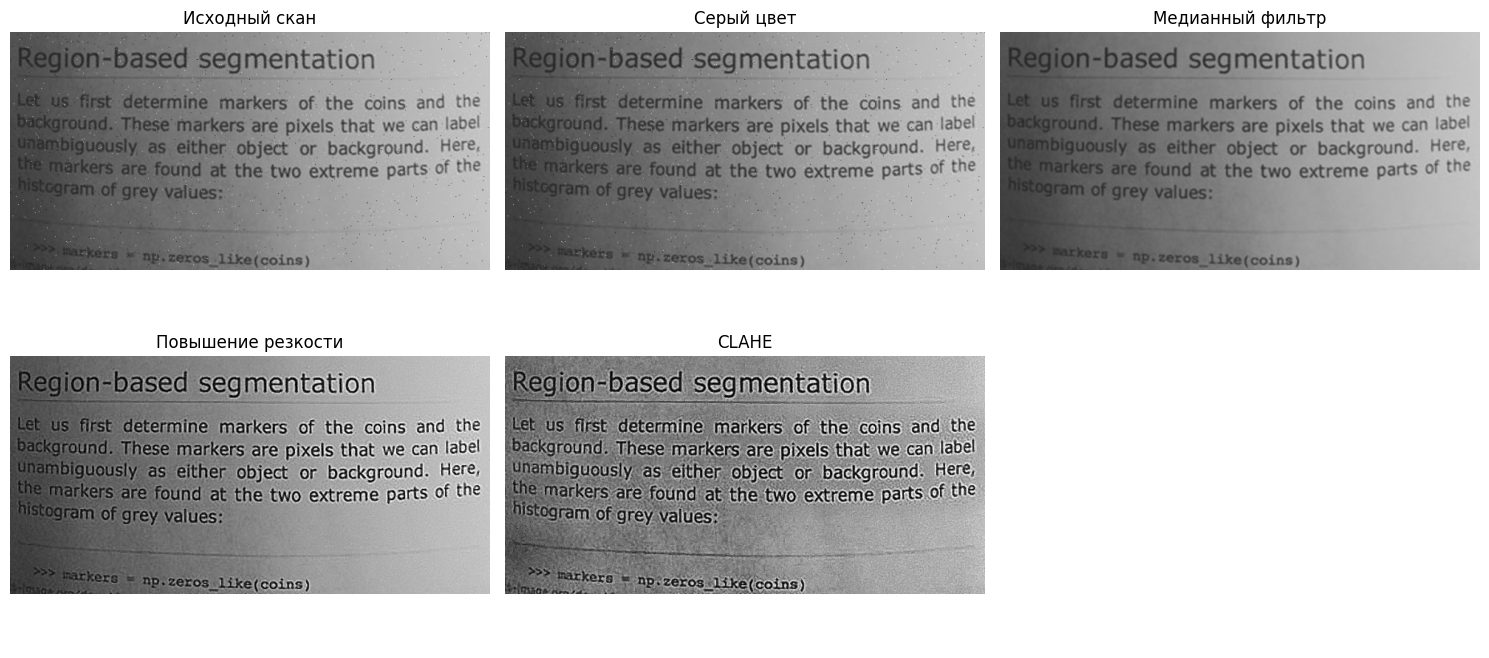

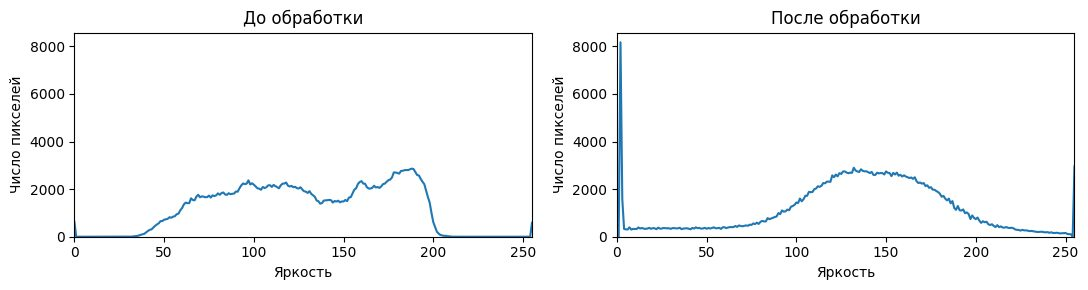

In [12]:
def improve_scan(image, median_kernel_size=3, sharp_kernel=None,
                 clahe_clip=2.0, clahe_grid=(8, 8), visible=True):
    """Убрать мелкий шум, повысить резкость и локальный контраст скана.

    image: uint8-массив в сером цвете, BGR или BGRA; исходный массив не меняется.
    Возвращает двумерный uint8-массив. visible включает вывод этапов и гистограмм.
    """
    if not isinstance(image, np.ndarray):
        raise TypeError('image должен быть массивом NumPy')
    if image.size == 0:
        raise ValueError('Изображение пустое')
    if image.dtype != np.uint8:
        raise TypeError('Ожидается изображение uint8 в диапазоне 0–255')
    if image.ndim not in (2, 3) or (image.ndim == 3 and image.shape[2] not in (1, 3, 4)):
        raise ValueError('Нужно серое изображение либо 3 или 4 канала')
    if not isinstance(median_kernel_size, (int, np.integer)) or median_kernel_size not in (3, 5):
        raise ValueError('Размер медианного фильтра должен быть 3 или 5')
    if not np.isfinite(clahe_clip) or clahe_clip <= 0:
        raise ValueError('clahe_clip должен быть положительным')
    if len(clahe_grid) != 2 or any(not isinstance(x, (int, np.integer)) or x <= 0 for x in clahe_grid):
        raise ValueError('clahe_grid должен содержать два положительных целых числа')

    # Альфа-канал накладываем на белый фон, затем переводим в серый цвет.
    if image.ndim == 2:
        gray = image.copy()
    elif image.shape[2] == 1:
        gray = image[:, :, 0].copy()
    elif image.shape[2] == 4:
        alpha = image[:, :, 3:4].astype(np.float32) / 255
        bgr = np.round(image[:, :, :3] * alpha + 255 * (1 - alpha)).astype(np.uint8)
        gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    else:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    if sharp_kernel is None:
        sharp_kernel = [[0, -0.25, 0], [-0.25, 2, -0.25], [0, -0.25, 0]]
    kernel = np.asarray(sharp_kernel, dtype=np.float32)
    if (kernel.ndim != 2 or not kernel.size or any(s % 2 == 0 for s in kernel.shape)
            or not np.isfinite(kernel).all()):
        raise ValueError('Ядро должно быть конечной матрицей с нечётными размерами')

    # Убираем точечный шум и повышаем резкость текста.
    median = cv2.medianBlur(gray, median_kernel_size)
    sharp = cv2.filter2D(median, cv2.CV_32F, kernel, borderType=cv2.BORDER_REFLECT_101)
    sharp = np.clip(np.round(sharp), 0, 255).astype(np.uint8)
    # Локально выравниваем контраст после фильтрации.
    result = cv2.createCLAHE(clipLimit=float(clahe_clip), tileGridSize=tuple(clahe_grid)).apply(sharp)

    if visible:
        show_images([('Исходный скан', image), ('Серый цвет', gray),
                     ('Медианный фильтр', median), ('Повышение резкости', sharp),
                     ('CLAHE', result)], '09_scan_stages.jpg', cols=3)
        fig, axes = plt.subplots(1, 2, figsize=(11, 3))
        for ax, title, values in zip(axes, ['До обработки', 'После обработки'], [gray, result]):
            ax.plot(cv2.calcHist([values], [0], None, [256], [0, 256]).ravel())
            ax.set(title=title, xlim=(0, 255), xlabel='Яркость', ylabel='Число пикселей')
        limit = max(ax.get_ylim()[1] for ax in axes)
        for ax in axes:
            ax.set_ylim(0, limit)
        fig.tight_layout()
        fig.savefig(OUT / '09_scan_histograms.png', dpi=120)
        plt.show()
        plt.close(fig)
    return result

# Делаем воспроизводимый пример: увеличиваем страницу вдвое, добавляем тень и шум.
page = read_image(EXAMPLES / 'page.png', cv2.IMREAD_GRAYSCALE)
page = cv2.resize(page, None, fx=2, fy=2, interpolation=cv2.INTER_CUBIC)
rng = np.random.default_rng(17)
shadow = np.linspace(0.58, 0.92, page.shape[1])[None, :]
scan_gray = np.clip((page.astype(np.float32) * 0.7 + 50) * shadow
                    + rng.normal(0, 2, page.shape), 0, 255).astype(np.uint8)
impulse = rng.random(page.shape)
scan_gray[impulse < 0.002] = 0
scan_gray[impulse > 0.998] = 255
save_image('09_scan_input.png', scan_gray)

# Сохраняем режим чтения с альфа-каналом, если он есть; иначе читаем цветной массив.
scan_path = OUT / '09_scan_input.png'
raw = read_image(scan_path, cv2.IMREAD_UNCHANGED)
scan = raw if raw.ndim == 3 and raw.shape[2] == 4 else read_image(scan_path, cv2.IMREAD_COLOR)
strong_kernel = np.array([[-1, -1, -1], [-1, 9, -1], [-1, -1, -1]], dtype=np.float32)
improved = improve_scan(scan, sharp_kernel=strong_kernel)
save_image('09_scan_improved.png', improved)

## Дополнительное задание:

- Поэкспериментируйте с параметрами медианного фильтра, ядром для фильтра повышения резкости и параметрами CLAHE для достижения наилучшего результата.
- Добавьте возможность передачи этих параметров в функцию `improve_scan` для более гибкой настройки обработки. В качестве параметров по умолчанию установите те, которые показали себя лучше всего по результатам экспериментов

Пример с параметрами:

```python
def improve_scan(image,
                 median_kernel_size=3,
                 sharp_kernel= np.array([[-1, -1, -1],
                                         [-1,  9, -1],
                                         [-1, -1, -1]]),
                 clahe_clip=2.0,
                 clahe_grid=(8,8),
                 visible=True):
    # Реализация с учетом переданных параметров
    ...
```

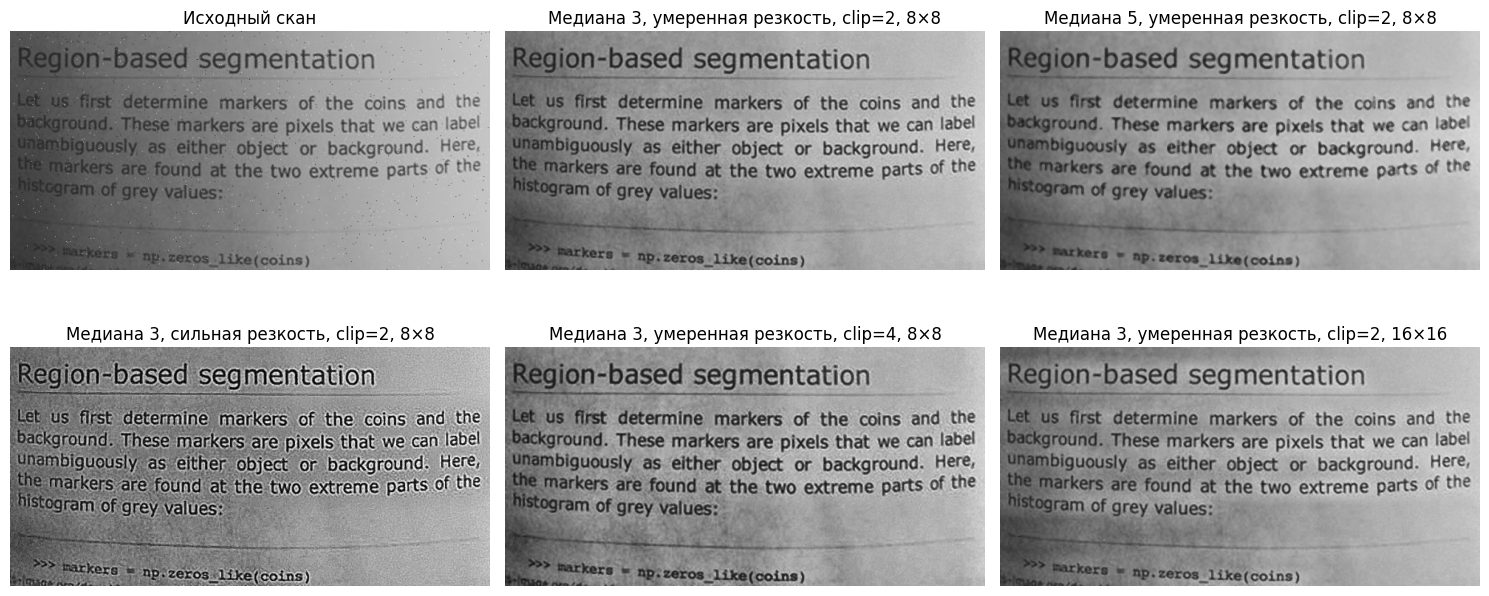

In [13]:
experiments = [
    ('Медиана 3, умеренная резкость, clip=2, 8×8', dict()),
    ('Медиана 5, умеренная резкость, clip=2, 8×8', dict(median_kernel_size=5)),
    ('Медиана 3, сильная резкость, clip=2, 8×8', dict(sharp_kernel=strong_kernel)),
    ('Медиана 3, умеренная резкость, clip=4, 8×8', dict(clahe_clip=4.0)),
    ('Медиана 3, умеренная резкость, clip=2, 16×16', dict(clahe_grid=(16, 16))),
]
comparisons = [('Исходный скан', scan)]
for title, options in experiments:
    comparisons.append((title, improve_scan(scan, visible=False, **options)))
show_images(comparisons, '09_scan_parameters.jpg', cols=3)
save_image('09_scan_selected.png', improve_scan(scan, visible=False))

Выбрал медиану 3, умеренное ядро резкости из функции, clipLimit=2 и сетку 8×8. Медиана 5 сильнее размывает буквы, а ядро с центральным коэффициентом 9 даёт грубые края. Выбранные параметры стоят в функции по умолчанию.